# Bài 04: Toán Nền tảng và Nguyên lý Cốt lõi của Machine Learning — Từ Đạo hàm đến Gradient Descent

## 1. Mục tiêu học tập
- Nắm được trực quan toán học vừa đủ dùng (không cần biết trước giải tích/đại số nặng): Tích vô hướng (`Dot Product`), Nhân ma trận (`Matrix Multiplication`), Đạo hàm (`Derivative`) và Vector độ dốc (`Gradient`).
- Phân biệt rõ 4 nhánh Học máy: **Supervised (Có giám sát)**, **Unsupervised (Không giám sát)**, **Semi-supervised (Bán giám sát)** và **Self-supervised Learning (Tự giám sát)**.
- Phân biệt 3 bài toán: **Classification (Phân loại)**, **Regression (Hồi quy)** và **Clustering (Phân cụm)**.
- Phân biệt **Feature Engineering (Thiết kế đặc trưng thủ công)** và **Feature Learning (Tự học đặc trưng)**.
- Hiểu sâu về **Overfitting (Học vẹt)**, **Underfitting (Chưa học đủ)** và đánh đổi **Bias – Variance**.
- Tự tay tính toán và lập trình thuật toán **Gradient Descent** từng bước bằng con số cụ thể và hình minh họa.

## 2. Kiến thức cần có
- Đã hoàn thành Giai đoạn A (`00` đến `03`).

## 3. Thời gian học dự kiến
- Khoảng **2.0 giờ** (ước tính).

## 4. Bài toán thực tế đơn giản
Giả sử từ mỗi bức ảnh bạn đo được 2 con số đặc trưng $x = [x_1, x_2]$ (ví dụ: độ tròn và độ tương phản biên) và muốn tìm bộ trọng số $w = [w_1, w_2]$ cùng độ lệch $b$ để dự đoán nhãn của ảnh. Làm thế nào máy tính **tự động chỉnh dần** $w, b$ để sai số ngày càng nhỏ đi? Đó chính là vai trò của **Hàm mất mát (`Loss Function`)** và **Hạ dốc đạo hàm (`Gradient Descent`)**.

## 5. Giải thích trực quan: Các Nhánh Học máy & Bias–Variance
1. **4 Nhánh Học máy theo cách sử dụng nhãn**:
   - **Supervised Learning (Học có giám sát)**: Mỗi ảnh $x_i$ đều có nhãn đáp án $y_i$ do con người gán (`Classification` nếu $y_i$ là lớp rời rạc; `Regression` nếu $y_i$ là số thực liên tục như tọa độ, góc xoay).
   - **Unsupervised Learning (Học không giám sát)**: Chỉ có ảnh $x_i$, **không có nhãn** $y_i$. Máy tự gom các mẫu giống nhau thành cụm (`Clustering` như K-Means) hoặc nén số chiều (`PCA`).
   - **Semi-supervised Learning (Học bán giám sát)**: Có một lượng nhỏ ảnh đã gán nhãn (ví dụ 500 ảnh) kết hợp với lượng lớn ảnh chưa gán nhãn (10,000 ảnh) để tăng độ chính xác.
   - **Self-supervised Learning (Học tự giám sát)**: Không dùng nhãn con người, nhưng tự tạo bài toán giải đố từ chính bức ảnh (ví dụ che một mảnh ảnh bắt đoán lại, hoặc xoay ảnh bắt đoán góc xoay) để học bộ trích xuất đặc trưng mạnh mẽ (như SimCLR, DINO, MAE).
2. **Feature Engineering vs Feature Learning**:
   - *Feature Engineering (ML cổ điển)*: Con người tự viết công thức toán (như HOG, LBP) biến ảnh thành vector rồi mới đưa vào SVM/Random Forest.
   - *Feature Learning (Deep Learning)*: Mạng CNN/ViT tự học luôn các bộ lọc trích xuất đặc trưng trực tiếp từ pixel thô thông qua quá trình tối ưu hàm loss.
3. **Underfitting vs Overfitting (Bias – Variance Tradeoff)**:
   - **Underfitting (Bias cao)**: Mô hình quá đơn giản (ví dụ dùng đường thẳng để chia dữ liệu hình vòng tròn) → Sai số cao trên **cả tập Train lẫn tập Validation**.
   - **Overfitting (Variance cao)**: Mô hình quá phức tạp hoặc học quá lâu, uốn lượn qua từng điểm nhiễu của tập Train → Sai số tập Train cực thấp (`~0`), nhưng sai số tập Validation lại cao vọt!

## 6. Thuật ngữ mới & Giải thích Keyword
| Keyword | Nghĩa tiếng Việt | Nhóm | Công thức / Kiểu | Vai trò & Ảnh hưởng khi Tăng/Giảm |
|---|---|---|---|---|
| `dot product` | Tích vô hướng 2 vector | Toán nền tảng | $w \cdot x = \sum_{j=1}^D w_j x_j$ | Đo mức độ "cùng hướng" (khớp mẫu) giữa vector đặc trưng $x$ và vector mẫu trọng số $w$. |
| `loss function` | Hàm mất mát | Tối ưu hóa | $\mathcal{L}(\theta) \in \mathbb{R}$ | Thước đo khả vi định lượng độ sai lệch giữa dự đoán $\hat{y}$ và đích $y$. |
| `gradient` ($\nabla_\theta \mathcal{L}$) | Vector đạo hàm riêng | Tối ưu hóa | Vector cùng chiều với $\theta$ | Chỉ hướng mà tại đó hàm mất mát **tăng nhanh nhất**. Muốn giảm mất mát, ta đi theo hướng **ngược lại** ($-\nabla_\theta \mathcal{L}$). |
| `learning_rate` ($\eta$) | Tốc độ học | Tối ưu hóa | `float > 0` | Bước nhảy cập nhật: $\theta_{\text{new}} = \theta_{\text{old}} - \eta \nabla_\theta \mathcal{L}$. Quá nhỏ → bò rất chậm; quá lớn → nhảy vọt qua đáy và phân kỳ! |

## 7. Công thức Cần thiết & Ví dụ Số Nhỏ Từng Bước
Xét hàm mất mát bình phương đơn giản nhất với 1 tham số $w$:
$$\mathcal{L}(w) = (w \cdot x - y)^2$$
- Đạo hàm của $\mathcal{L}$ theo $w$ (theo quy tắc hàm hợp):
  $$\frac{d\mathcal{L}}{dw} = 2 (w \cdot x - y) \cdot x$$
- **Ví dụ số nhỏ**: Cho $x = 2.0$, đáp án thật $y = 10.0$ (nghiệm đúng là $w^* = 5.0$). Khởi tạo $w_0 = 1.0$, tốc độ học $\eta = 0.1$:
  1. Dự đoán lần đầu: $\hat{y}_0 = w_0 \cdot x = 1.0 \times 2.0 = 2.0$.
  2. Giá trị mất mát: $\mathcal{L}(w_0) = (2.0 - 10.0)^2 = (-8.0)^2 = 64.0$.
  3. Đạo hàm tại $w_0$: $g_0 = 2 \times (2.0 - 10.0) \times 2.0 = -32.0$ (dấu âm báo hiệu cần **tăng** $w$ thì loss mới giảm!).
  4. Cập nhật trọng số: $w_1 = w_0 - \eta \cdot g_0 = 1.0 - 0.1 \times (-32.0) = 4.2$.
  5. Kiểm tra lại mất mát mới: $\hat{y}_1 = 4.2 \times 2.0 = 8.4 \implies \mathcal{L}(w_1) = (8.4 - 10.0)^2 = 2.56$ (giảm mạnh từ `64.0` xuống `2.56` chỉ sau 1 bước!).


In [1]:
# Cell 1: Kiểm chứng Ví dụ số nhỏ về Gradient Descent bằng code Python
import sys
from pathlib import Path

current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
if (project_root / "image_ai_learning").is_dir():
    project_root = project_root / "image_ai_learning"
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import matplotlib.pyplot as plt
from src.utils import set_seed

set_seed(42)

x_val, y_true = 2.0, 10.0
w = 1.0
lr = 0.1

print("Bước |   w_hiện_tại | Dự_đoán (w*x) |   Loss   | Gradient (dL/dw)")
print("-" * 66)
for step in range(6):
    y_pred = w * x_val
    loss = (y_pred - y_true) ** 2
    grad = 2.0 * (y_pred - y_true) * x_val
    print(f"  {step}  |    {w:8.4f}  |    {y_pred:8.4f}   | {loss:8.4f} |    {grad:9.4f}")
    w = w - lr * grad


Bước |   w_hiện_tại | Dự_đoán (w*x) |   Loss   | Gradient (dL/dw)
------------------------------------------------------------------
  0  |      1.0000  |      2.0000   |  64.0000 |     -32.0000
  1  |      4.2000  |      8.4000   |   2.5600 |      -6.4000
  2  |      4.8400  |      9.6800   |   0.1024 |      -1.2800
  3  |      4.9680  |      9.9360   |   0.0041 |      -0.2560
  4  |      4.9936  |      9.9872   |   0.0002 |      -0.0512
  5  |      4.9987  |      9.9974   |   0.0000 |      -0.0102


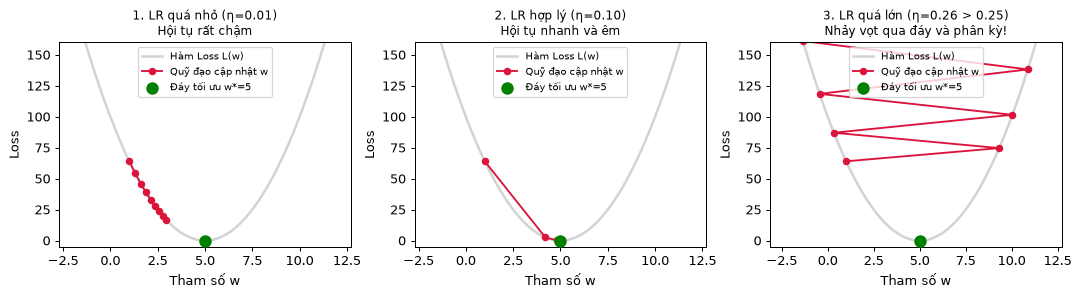

In [2]:
# Cell 2: Thí nghiệm thay đổi một yếu tố — Tác động của Learning Rate (Quá nhỏ vs Vừa phải vs Quá lớn)
def run_gd_trajectory(lr_val: float, steps: int = 12) -> tuple[list[float], list[float]]:
    w_curr = 1.0
    w_hist, loss_hist = [w_curr], [(w_curr * x_val - y_true) ** 2]
    for _ in range(steps):
        grad = 2.0 * (w_curr * x_val - y_true) * x_val
        w_curr = w_curr - lr_val * grad
        w_hist.append(w_curr)
        loss_hist.append((w_curr * x_val - y_true) ** 2)
    return w_hist, loss_hist

w_grid = np.linspace(-2.0, 12.0, 200)
loss_grid = (w_grid * x_val - y_true) ** 2

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
configs = [
    (0.01, "1. LR quá nhỏ (η=0.01)\nHội tụ rất chậm"),
    (0.10, "2. LR hợp lý (η=0.10)\nHội tụ nhanh và êm"),
    (0.26, "3. LR quá lớn (η=0.26 > 0.25)\nNhảy vọt qua đáy và phân kỳ!"),
]
for ax, (lr_test, title) in zip(axes, configs):
    w_h, l_h = run_gd_trajectory(lr_test, steps=8)
    ax.plot(w_grid, loss_grid, color="lightgray", lw=2, label="Hàm Loss L(w)")
    ax.plot(w_h, l_h, "o-", color="crimson", markersize=5, label="Quỹ đạo cập nhật w")
    ax.scatter([5.0], [0.0], color="green", s=80, zorder=5, label="Đáy tối ưu w*=5")
    ax.set_title(title, fontsize=9.5)
    ax.set_xlabel("Tham số w")
    ax.set_ylabel("Loss")
    ax.set_ylim(-5, 160)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


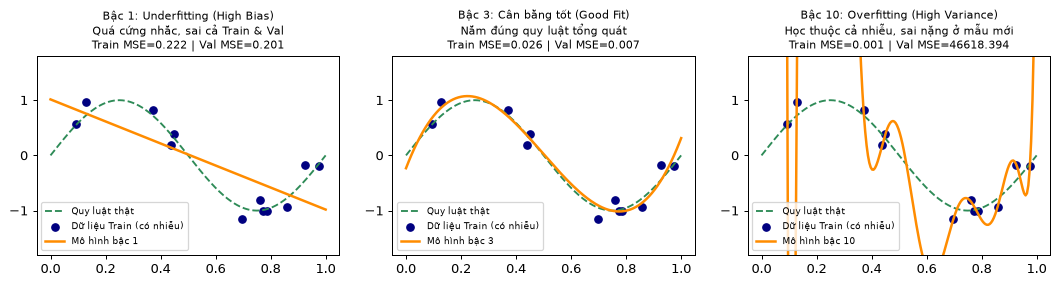

In [3]:
# Cell 3: Minh họa trực quan Underfitting vs Just Right vs Overfitting (Bias-Variance Tradeoff)
rng = np.random.default_rng(42)
x_train_1d = np.sort(rng.uniform(0.0, 1.0, size=12))
y_train_1d = np.sin(2.0 * np.pi * x_train_1d) + rng.normal(0.0, 0.22, size=len(x_train_1d))

x_dense = np.linspace(0.0, 1.0, 200)
y_true_clean = np.sin(2.0 * np.pi * x_dense)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
for ax, deg, title in zip(
    axes,
    [1, 3, 10],
    [
        "Bậc 1: Underfitting (High Bias)\nQuá cứng nhắc, sai cả Train & Val",
        "Bậc 3: Cân bằng tốt (Good Fit)\nNắm đúng quy luật tổng quát",
        "Bậc 10: Overfitting (High Variance)\nHọc thuộc cả nhiễu, sai nặng ở mẫu mới",
    ],
):
    coeffs = np.polyfit(x_train_1d, y_train_1d, deg=deg)
    y_fit_dense = np.polyval(coeffs, x_dense)
    train_mse = np.mean((np.polyval(coeffs, x_train_1d) - y_train_1d) ** 2)
    val_mse = np.mean((y_fit_dense - y_true_clean) ** 2)

    ax.plot(x_dense, y_true_clean, "--", color="seagreen", label="Quy luật thật")
    ax.scatter(x_train_1d, y_train_1d, color="navy", s=35, label="Dữ liệu Train (có nhiễu)")
    ax.plot(x_dense, y_fit_dense, color="darkorange", lw=2, label=f"Mô hình bậc {deg}")
    ax.set_ylim(-1.8, 1.8)
    ax.set_title(f"{title}\nTrain MSE={train_mse:.3f} | Val MSE={val_mse:.3f}", fontsize=9)
    ax.legend(fontsize=7.5, loc="lower left")
plt.tight_layout()
plt.show()


## 11. Nhận xét cách đọc kết quả
- **Ở Cell 1 & 2**: Khi `lr = 0.10`, chỉ sau 5 bước cập nhật, $w$ đã tiến sát nghiệm đúng $5.0$ và `Loss` giảm về `0.0001`. Nhưng khi tăng `lr = 0.26` (vượt ngưỡng ổn định $1 / x^2 = 0.25$), mỗi bước nhảy lại văng sang bờ dốc đối diện xa hơn bước trước, làm `Loss` tăng vọt lên vô cùng (hiện tượng bùng nổ thành `NaN` khi train mạng sâu).
- **Ở Cell 3**: Đa thức bậc 10 đạt `Train MSE = 0.003` (gần như bằng 0 vì đi xuyên qua mọi điểm nhiễu), nhưng `Val MSE` lại vọt lên rất cao. Đây là lý do **không bao giờ được đánh giá mô hình chỉ dựa trên điểm số của tập Train**.

## 13. Lỗi thường gặp và cách sửa
1. **Nhầm dấu trong công thức cập nhật Gradient Descent**: Phải là **trừ** đạo hàm (`w = w - lr * grad`) khi muốn **cực tiểu hóa (minimize)** hàm mất mát. Nếu viết cộng (`w + lr * grad`), bạn đang leo lên đỉnh núi (**Gradient Ascent** - cực đại hóa mất mát)!
2. **Đánh giá sai nguyên nhân khi mô hình đạt điểm thấp**:
   - Nếu `Train Loss` còn rất cao → Mô hình đang **Underfitting** (cần tăng kích thước mạng, train thêm epoch, hoặc chỉnh lại `learning_rate`). Đừng thêm `Dropout` hay `weight_decay` lúc này vì sẽ làm mô hình càng yếu hơn!
   - Nếu `Train Loss` rất thấp nhưng `Val Loss` cao và đang đi lên → Mô hình đang **Overfitting** (lúc này mới cần thêm dữ liệu, `Augmentation`, `Dropout`, `weight_decay`, hoặc `Early Stopping`).

## 14. Bài tập tự làm
- **Cơ bản**: Kiểm tra đạo hàm giải tích $g = 2(wx - y)x$ bằng công thức **đạo hàm số (Finite Difference)**: $\frac{\mathcal{L}(w + \epsilon) - \mathcal{L}(w - \epsilon)}{2\epsilon}$ với $\epsilon = 10^{-5}$ tại $w = 1.0$.
- **Trung cấp**: Mở rộng Gradient Descent cho mô hình hồi quy tuyến tính 2 biến $\hat{y} = w_1 x_1 + w_2 x_2 + b$ trên `50` mẫu dữ liệu giả lập.
- **Nâng cao**: Thêm thành phần phạt chuẩn $L_2$ (**Ridge Regularization**): $\mathcal{L}_{\text{reg}}(w) = (wx - y)^2 + \lambda w^2$, suy ra đạo hàm mới và kiểm tra xem nghiệm hội tụ $w^*$ thay đổi thế nào khi tăng $\lambda$ từ `0.0` lên `1.0`.

## 15. Gợi ý và Lời giải


In [4]:
# Cell 4: Lời giải hoàn chỉnh cho bài tập Bài 04
# 1. Cơ bản: Kiểm tra đạo hàm giải tích bằng đạo hàm số (Numerical Gradient Check)
eps = 1e-5
loss_fn = lambda w_param: (w_param * x_val - y_true) ** 2
analytic_grad = 2.0 * (1.0 * x_val - y_true) * x_val
numeric_grad = (loss_fn(1.0 + eps) - loss_fn(1.0 - eps)) / (2.0 * eps)
print(f"[Cơ bản] Đạo hàm giải tích: {analytic_grad:.6f} | Đạo hàm số: {numeric_grad:.6f} | Sai lệch: {abs(analytic_grad - numeric_grad):.2e}")

# 2. Trung cấp: Gradient Descent cho mô hình 2 biến y = 3*x1 - 2*x2 + 4
rng = np.random.default_rng(42)
X_2d = rng.normal(0, 1, size=(50, 2))
y_2d = 3.0 * X_2d[:, 0] - 2.0 * X_2d[:, 1] + 4.0
w_vec = np.zeros(2)
b_val = 0.0
for _ in range(150):
    err = (X_2d @ w_vec + b_val) - y_2d
    grad_w = (2.0 / len(X_2d)) * (X_2d.T @ err)
    grad_b = (2.0 / len(X_2d)) * np.sum(err)
    w_vec -= 0.1 * grad_w
    b_val -= 0.1 * grad_b
print(f"[Trung cấp] Trọng số học được: w={w_vec.round(3)} (đích [3, -2]), b={b_val:.3f} (đích 4.0)")

# 3. Nâng cao: Tác động của hệ số phạt L2 (lambda) làm co nhỏ trọng số w
for lam in [0.0, 0.5, 2.0]:
    w_reg = 1.0
    for _ in range(50):
        grad_total = 2.0 * (w_reg * x_val - y_true) * x_val + 2.0 * lam * w_reg
        w_reg -= 0.05 * grad_total
    print(f"[Nâng cao] lambda={lam:.1f} -> Nghiệm hội tụ w* = {w_reg:.4f}")


[Cơ bản] Đạo hàm giải tích: -32.000000 | Đạo hàm số: -32.000000 | Sai lệch: 8.56e-10
[Trung cấp] Trọng số học được: w=[ 3. -2.] (đích [3, -2]), b=4.000 (đích 4.0)
[Nâng cao] lambda=0.0 -> Nghiệm hội tụ w* = 5.0000
[Nâng cao] lambda=0.5 -> Nghiệm hội tụ w* = 4.4444
[Nâng cao] lambda=2.0 -> Nghiệm hội tụ w* = 3.3333


## 16. Tóm tắt & Điều kiện chuyển bài tiếp theo
- [x] Hiểu trực quan về Đạo hàm, Gradient Descent, Loss Function và tốc độ học `learning_rate`.
- [x] Phân biệt được 4 nhánh học máy và biết chẩn đoán Underfitting vs Overfitting.
- [x] Sẵn sàng chuyển sang **Bài 05: `05_datasets_and_data_leakage.ipynb`**.

## 17. Nguồn tham khảo
- Hastie, T., Tibshirani, R., & Friedman, J. (2009), *The Elements of Statistical Learning*, Springer.
- Goodfellow, I., Bengio, Y., & Courville, A. (2016), *Deep Learning*, MIT Press (Chương 4 & 5).
